# Used Car Price Prediction (Quikr dataset)

**Goal:** predict the selling price (in ₹) of a used car from its name, company, manufacturing year, kilometres driven and fuel type.

**Type of problem:** supervised learning, regression.

**Workflow:** load data → clean the messy columns → explore → build a preprocessing + model pipeline → compare models → tune the best one → save it for the Flask web app (`app.py`).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style='whitegrid')

## 1. Load the data

In [2]:
raw = pd.read_csv('quikr_car.csv')
print('Shape:', raw.shape)
raw.head(10)

Shape: (892, 6)


,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel
5,Ford EcoSport Titanium 1.5L TDCi,Ford,2015,Ask For Price,"59,000 kms",Diesel
6,Ford Figo,Ford,2012,"1,75,000","41,000 kms",Diesel
7,Hyundai Eon,Hyundai,2013,"1,90,000","25,000 kms",Petrol
8,Ford EcoSport Ambiente 1.5L TDCi,Ford,2016,"8,30,000","24,530 kms",Diesel
9,Maruti Suzuki Alto K10 VXi AMT,Maruti,2015,"2,50,000","60,000 kms",Petrol


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 892 entries, 0 to 891
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   name        892 non-null    str  
 1   company     892 non-null    str  
 2   year        892 non-null    str  
 3   Price       892 non-null    str  
 4   kms_driven  840 non-null    str  
 5   fuel_type   837 non-null    str  
dtypes: str(6)
memory usage: 41.9 KB


## 2. Data cleaning

The raw data was scraped from a classified-ads site, so it is very messy. Problems found:

| Column | Problem | Fix |
|---|---|---|
| `year` | contains text such as `150k`, `...`, `Zest` | keep only numeric years |
| `Price` | commas (`4,25,000`) and `Ask For Price` | remove commas, drop rows without a price |
| `kms_driven` | text like `45,000 kms`, missing values, a stray `Petrol` | extract the number, drop invalid rows |
| `fuel_type` | missing values | drop rows |
| `company` | junk values (`Sale`, `I`, `URJENT`…) and mixed case (`MARUTI`, `tata`) | standardise case, keep real car brands only |
| `name` | very long and unique (525 values) | keep the first three words |
| `Price` | a few extreme outliers | remove prices above ₹20 lakh (luxury cars are too few to learn from) |

In [4]:
df = raw.copy()

# year: keep only numeric values
df = df[df['year'].str.isnumeric()]
df['year'] = df['year'].astype(int)

# Price: remove 'Ask For Price' and convert to int
df = df[df['Price'] != 'Ask For Price']
df['Price'] = df['Price'].str.replace(',', '').astype(int)

# kms_driven and fuel_type: drop missing, extract number
df = df.dropna(subset=['kms_driven', 'fuel_type'])
df['kms_driven'] = df['kms_driven'].str.split().str[0].str.replace(',', '')
df = df[df['kms_driven'].str.isnumeric()]
df['kms_driven'] = df['kms_driven'].astype(int)

# company: standardise case and keep real brands only
df['company'] = df['company'].str.strip().str.title()
brands = ['Audi', 'Bmw', 'Chevrolet', 'Datsun', 'Fiat', 'Force', 'Ford', 'Hindustan', 'Honda',
          'Hyundai', 'Jaguar', 'Jeep', 'Land', 'Mahindra', 'Maruti', 'Mercedes', 'Mini',
          'Mitsubishi', 'Nissan', 'Renault', 'Skoda', 'Tata', 'Toyota', 'Volkswagen', 'Volvo']
df = df[df['company'].isin(brands)]
df['company'] = df['company'].replace({'Bmw': 'BMW'})

# name: keep the first three words
df['name'] = df['name'].str.split().str[:3].str.join(' ')

# outliers
df = df[df['Price'] < 2_000_000]

df = df.reset_index(drop=True)
print('Rows before:', len(raw), '| rows after cleaning:', len(df))
df.to_csv('cleaned_car.csv', index=False)
df.head()

Rows before: 892 | rows after cleaning: 808


,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing,Hyundai,2007,80000,45000,Petrol
1,Mahindra Jeep CL550,Mahindra,2006,425000,40,Diesel
2,Hyundai Grand i10,Hyundai,2014,325000,28000,Petrol
3,Ford EcoSport Titanium,Ford,2014,575000,36000,Diesel
4,Ford Figo,Ford,2012,175000,41000,Diesel


In [5]:
print(df.isna().sum().sum(), 'missing values left')
df.describe()

0 missing values left


,year,Price,kms_driven
count,808.000000,8.080000e+02,808.000000
mean,2012.418317,3.836406e+05,46501.012376
std,4.010304,3.272027e+05,34369.741558
min,1995.000000,3.000000e+04,0.000000
25%,2010.000000,1.750000e+05,27000.000000
50%,2013.000000,2.999990e+05,41000.000000
75%,2015.000000,4.899990e+05,57230.750000
max,2019.000000,1.900000e+06,400000.000000


## 3. Exploratory data analysis

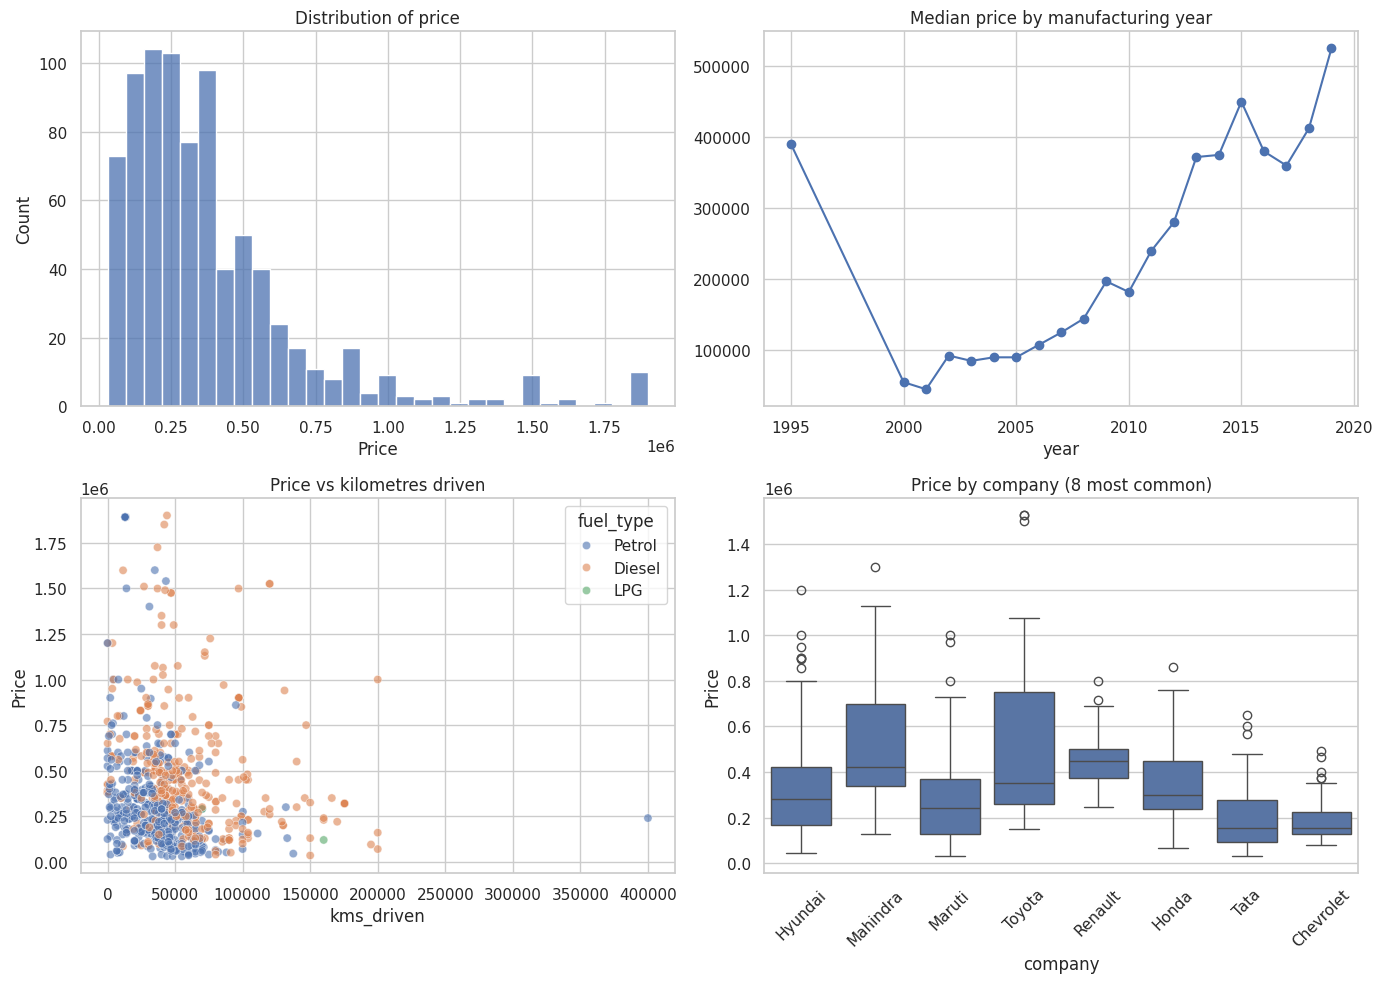

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df['Price'], bins=30, ax=ax[0, 0])
ax[0, 0].set_title('Distribution of price')

df.groupby('year')['Price'].median().plot(marker='o', ax=ax[0, 1])
ax[0, 1].set_title('Median price by manufacturing year')

sns.scatterplot(data=df, x='kms_driven', y='Price', hue='fuel_type', alpha=0.6, ax=ax[1, 0])
ax[1, 0].set_title('Price vs kilometres driven')

top = df['company'].value_counts().head(8).index
sns.boxplot(data=df[df['company'].isin(top)], x='company', y='Price', ax=ax[1, 1])
ax[1, 1].set_title('Price by company (8 most common)')
ax[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [7]:
print(df.groupby('fuel_type')['Price'].agg(['count', 'mean', 'median']).round(0))
df.groupby('company')['Price'].median().sort_values(ascending=False).head(10)

           count      mean    median
fuel_type                           
Diesel       380  465058.0  385000.0
LPG            2  205000.0  205000.0
Petrol       426  311854.0  232500.0


company
Mini          1891111.0
Volvo         1850000.0
Mitsubishi    1482500.0
Audi          1350000.0
Mercedes      1225000.0
BMW           1050000.0
Jeep           950000.0
Force          580000.0
Ford           465000.0
Renault        449999.0
Name: Price, dtype: float64

**Observations**
- Price is right-skewed: most cars are cheap and a few are very expensive, so we train on `log(price)` to make the model stable.
- Newer cars cost more; price rises steadily with manufacturing year.
- Higher kilometres driven generally means a lower price.
- Brand matters a lot (premium brands sit above Maruti or Tata).

## 4. Build the model

- **Features:** `name`, `company`, `year`, `kms_driven`, `fuel_type`
- **Target:** `Price`
- Text columns are one-hot encoded, numeric columns are scaled, and the price is log-transformed. Everything sits inside one `Pipeline`, so the same preprocessing is applied automatically when the web app makes a prediction.

In [8]:
X = df[['name', 'company', 'year', 'kms_driven', 'fuel_type']]
y = df['Price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

cat_cols = ['name', 'company', 'fuel_type']
num_cols = ['year', 'kms_driven']

def make_pipeline(model):
    prep = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('num', StandardScaler(), num_cols),
    ])
    return Pipeline([
        ('prep', prep),
        ('model', TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)),
    ])

Train: (646, 5) | Test: (162, 5)


## 5. Compare models

In [9]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}

rows = []
for name, model in models.items():
    pipe = make_pipeline(model)
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring='r2').mean()
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({
        'Model': name,
        'CV R2': round(cv, 3),
        'Test R2': round(r2_score(y_test, pred), 3),
        'MAE (Rs)': round(mean_absolute_error(y_test, pred)),
        'RMSE (Rs)': round(np.sqrt(mean_squared_error(y_test, pred))),
    })

results = pd.DataFrame(rows).sort_values('Test R2', ascending=False).reset_index(drop=True)
results

,Model,CV R2,Test R2,MAE (Rs),RMSE (Rs)
0,Linear Regression,0.686,0.765,79147,149630
1,Ridge Regression,0.689,0.730,90268,160524
2,Random Forest,0.646,0.607,96495,193639
3,Gradient Boosting,0.639,0.531,124372,211433


## 6. Hyper-parameter tuning

In [10]:
# Regularised linear models do best here (small dataset, many one-hot columns),
# so we tune the strength of the regularisation (alpha) of Ridge.
param_grid = {'model__regressor__alpha': [0.1, 0.3, 1, 3, 10, 30]}
grid = GridSearchCV(make_pipeline(Ridge()), param_grid, cv=5, scoring='r2')
grid.fit(X_train, y_train)

print('Best parameters:', grid.best_params_)
print('Best CV R2     :', round(grid.best_score_, 3))

tuned = grid.best_estimator_
pred = tuned.predict(X_test)
tuned_scores = {
    'r2': r2_score(y_test, pred),
    'mae': mean_absolute_error(y_test, pred),
    'rmse': np.sqrt(mean_squared_error(y_test, pred)),
}
print('Test R2 :', round(tuned_scores['r2'], 3))
print('Test MAE: Rs', round(tuned_scores['mae']))
print('Test RMSE: Rs', round(tuned_scores['rmse']))

Best parameters: {'model__regressor__alpha': 0.3}
Best CV R2     : 0.698
Test R2 : 0.756
Test MAE: Rs 81593
Test RMSE: Rs 152480


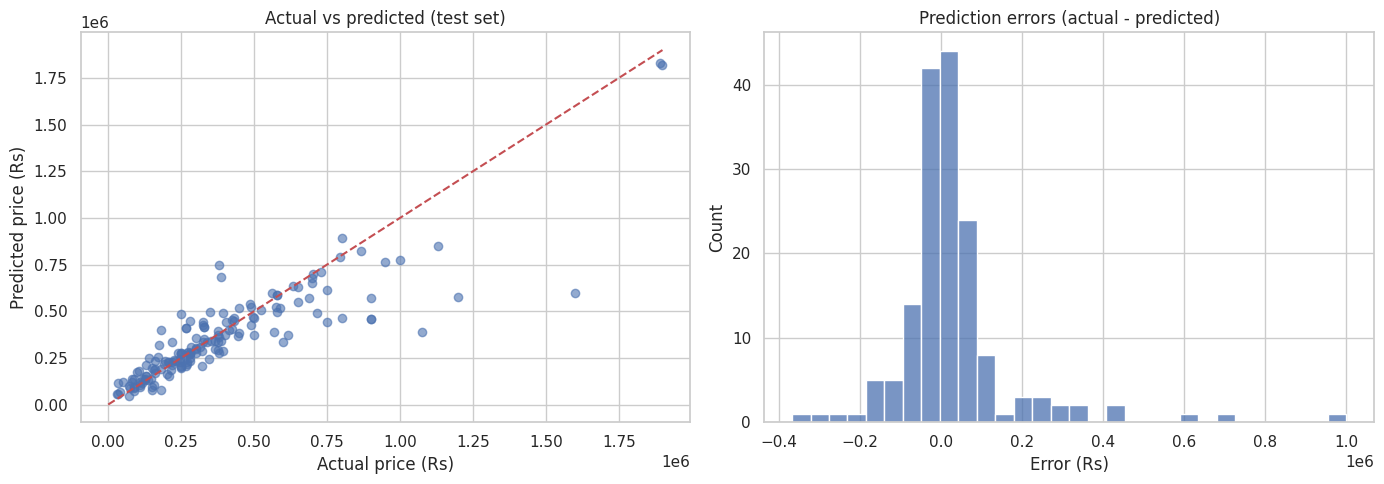

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(y_test, pred, alpha=0.6)
lim = [0, max(y_test.max(), pred.max())]
ax[0].plot(lim, lim, 'r--')
ax[0].set_xlabel('Actual price (Rs)')
ax[0].set_ylabel('Predicted price (Rs)')
ax[0].set_title('Actual vs predicted (test set)')

sns.histplot(y_test - pred, bins=30, ax=ax[1])
ax[1].set_title('Prediction errors (actual - predicted)')
ax[1].set_xlabel('Error (Rs)')

plt.tight_layout()
plt.show()

## 7. Save the model for the web app

The final model is re-trained on the **full** cleaned dataset (more data = better predictions), then saved together with a small lookup file that the web form uses to fill its drop-downs.

In [12]:
final_model = grid.best_estimator_
final_model.fit(X, y)
joblib.dump(final_model, 'model.joblib')

lookup = {c: sorted(g['name'].unique().tolist()) for c, g in df.groupby('company')}
meta = {
    'model': 'Ridge Regression (tuned)',
    'r2': round(tuned_scores['r2'], 3),
    'mae': round(tuned_scores['mae']),
    'rmse': round(tuned_scores['rmse']),
    'rows': int(len(df)),
    'year_min': int(df['year'].min()),
    'year_max': int(df['year'].max()),
    'fuel_types': sorted(df['fuel_type'].unique().tolist()),
    'companies': lookup,
}
with open('metadata.json', 'w') as f:
    json.dump(meta, f, indent=2)
print('Saved: model.joblib, metadata.json')

Saved: model.joblib, metadata.json


## 8. Try the saved model

In [13]:
model = joblib.load('model.joblib')

def predict_price(name, company, year, kms_driven, fuel_type):
    row = pd.DataFrame([{'name': name, 'company': company, 'year': year,
                         'kms_driven': kms_driven, 'fuel_type': fuel_type}])
    return round(float(model.predict(row)[0]), -3)

print('Maruti Suzuki Swift, 2015, 40,000 km, Petrol  -> Rs', predict_price('Maruti Suzuki Swift', 'Maruti', 2015, 40000, 'Petrol'))
print('Hyundai Grand i10, 2018, 25,000 km, Petrol    -> Rs', predict_price('Hyundai Grand i10', 'Hyundai', 2018, 25000, 'Petrol'))
print('Mahindra Scorpio, 2012, 90,000 km, Diesel     -> Rs', predict_price('Mahindra Scorpio S10', 'Mahindra', 2012, 90000, 'Diesel'))

Maruti Suzuki Swift, 2015, 40,000 km, Petrol  -> Rs 312000.0
Hyundai Grand i10, 2018, 25,000 km, Petrol    -> Rs 472000.0
Mahindra Scorpio, 2012, 90,000 km, Diesel     -> Rs 366000.0


## 9. Conclusion and future scope

- Cleaning the scraped data was the most important step: the raw file had text in numeric columns, missing values and junk brand names.
- With only ~800 rows and many one-hot brand/model columns, regularised linear models generalise better than Random Forest or Gradient Boosting, so the tuned Ridge model is used in the web app.
- The model error (MAE) is shown in the results above and on the web page, so users know how much to trust an estimate.

**Possible improvements:** add engine size, transmission, owner count and city; use a larger dataset; try XGBoost / LightGBM; deploy the app online (Render, Hugging Face Spaces).